# №1. Цветное изображение и яркость


## Импорты


In [10]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [11]:
plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'
plt.rcParams['image.interpolation'] = 'nearest'


def to_uint8(image):
    return np.clip(np.rint(image), 0, 255).astype(np.uint8)


def show_images(images, titles, cols=3):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.2 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, image, title in zip(axes.flat, images, titles):
        if image.ndim == 2:
            ax.imshow(image, vmin=0, vmax=255)
        else:
            ax.imshow(to_uint8(image))
        ax.set_title(title)
    fig.tight_layout()
    plt.show()

rng = np.random.default_rng(42)

Читаем JPEG и GIF в массив NumPy. Получаем серое изображение тремя способами и строим палитры из 100 цветов с заданной яркостью.

Pillow декодирует файлы. Все операции с каналами и яркостью выполняет NumPy. Цветовые каналы представлены числами от 0 до 255.


## 1. Чтение и размер изображения

Форма RGB-массива — `(высота, ширина, 3)`. Число 3 задаёт количество каналов. В каждом 8-битном канале доступны 256 уровней. Число уровней, встреченных в конкретном файле, считаем отдельно.

У GIF выбираем кадр по номеру `frame`, начиная с нуля. Палитру GIF преобразуем в RGB.


JPEG: shape=(300, 451, 3); H=300, W=451, каналов=3
Тип: uint8 ; доступных уровней на канал: 256
Встреченных уровней R, G, B: [215, 187, 190]
GIF, кадр 0: shape=(300, 451, 3); H=300, W=451, каналов=3
Тип: uint8 ; доступных уровней на канал: 256
Встреченных уровней R, G, B: [96, 105, 125]


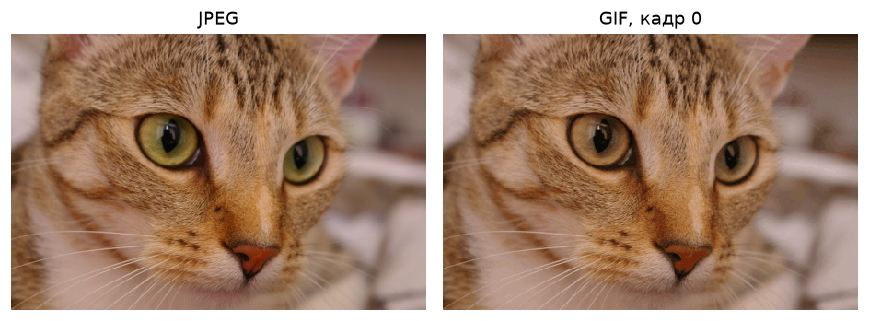

In [12]:
def image_to_array(path, frame=0):
    """Прочитать выбранный кадр как RGB-массив uint8."""
    with Image.open(path) as image:
        image.seek(frame)
        return np.array(image.convert('RGB'))


rgb = image_to_array('data/scene.jpg')
gif_rgb = image_to_array('data/scene.gif', frame=0)
for name, image in [('JPEG', rgb), ('GIF, кадр 0', gif_rgb)]:
    height, width, channels = image.shape
    print(f'{name}: shape={image.shape}; H={height}, W={width}, каналов={channels}')
    print('Тип:', image.dtype, '; доступных уровней на канал:', np.iinfo(image.dtype).max + 1)
    print('Встреченных уровней R, G, B:', [np.unique(image[..., c]).size for c in range(3)])

show_images([rgb, gif_rgb], ['JPEG', 'GIF, кадр 0'], cols=2)

## 2–3. Три формулы серого изображения

Среднее арифметическое: $Y=(R+G+B)/3$.

ITU-R BT.601: $Y=0.299R+0.587G+0.114B$.

ITU-R BT.709: $Y=0.2126R+0.7152G+0.0722B$.

Формулы применяем к записанным в файле RGB-значениям. Это взвешенная яркость кодированных каналов (luma). Для расчёта физической светимости требуется учёт передаточной функции цветового пространства.

Перед сложением переводим массив в `float64`, затем округляем и ограничиваем результат диапазоном 0–255.


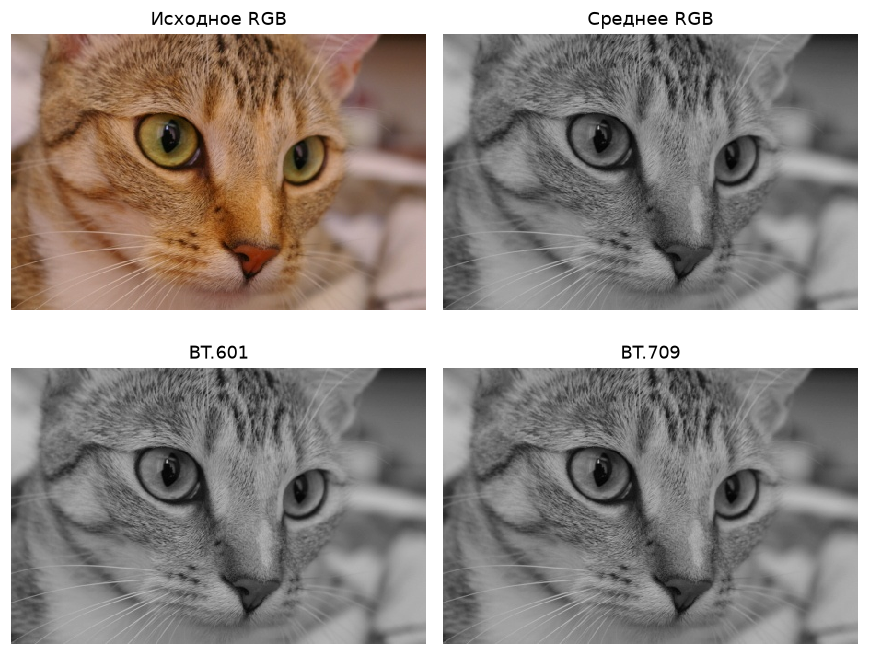

Серый массив: (300, 451)
Средняя абсолютная разность BT.601 и BT.709: 2.11


In [13]:
WEIGHTS_601 = np.array([0.299, 0.587, 0.114])
WEIGHTS_709 = np.array([0.2126, 0.7152, 0.0722])


def grayscale_mean(image):
    return image.astype(float).mean(axis=2)


def grayscale_weighted(image, weights):
    return image.astype(float) @ weights


gray_mean = grayscale_mean(rgb)
gray_601 = grayscale_weighted(rgb, WEIGHTS_601)
gray_709 = grayscale_weighted(rgb, WEIGHTS_709)
show_images([rgb, to_uint8(gray_mean), to_uint8(gray_601), to_uint8(gray_709)],
            ['Исходное RGB', 'Среднее RGB', 'BT.601', 'BT.709'], cols=2)

print('Серый массив:', gray_709.shape)
print('Средняя абсолютная разность BT.601 и BT.709:', round(np.abs(gray_601 - gray_709).mean(), 3))

## 4. Сто цветов одинаковой яркости

Фиксируем $Y=128$. Случайно выбираем $R$ и $B$, затем вычисляем

$$G=\frac{128-w_R R-w_B B}{w_G}.$$

Для каждого набора весов получаем отдельную палитру 10×10. Случайное зерно фиксировано, поэтому повторный запуск воспроизводит те же цвета. Для выбранной яркости 128 оба набора весов допускают весь диапазон $R,B\in[0,255]$.


BT.601: 100 цветов; ошибка float=2.84e-14, ошибка uint8=0.460


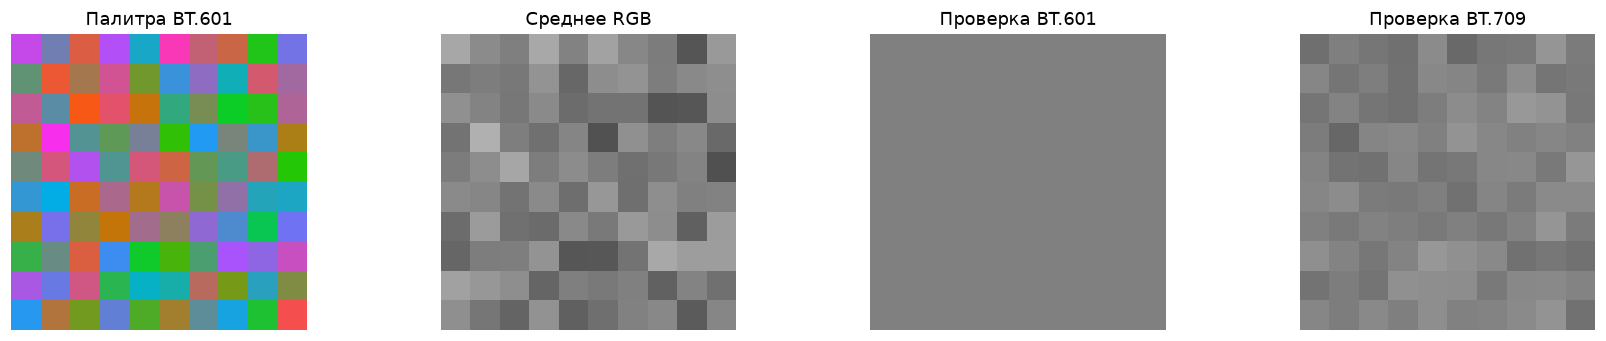

BT.709: 100 цветов; ошибка float=2.84e-14, ошибка uint8=0.438


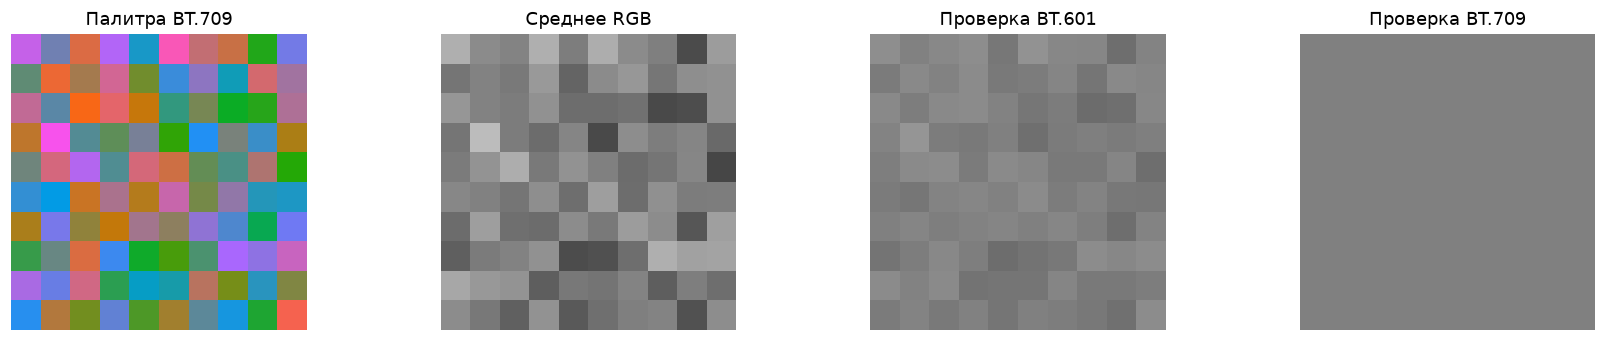

In [14]:
def equal_luma_palette(weights, target=128, seed=42):
    generator = np.random.default_rng(seed)
    red = generator.uniform(0, 255, (10, 10))
    blue = generator.uniform(0, 255, (10, 10))
    green = (target - weights[0] * red - weights[2] * blue) / weights[1]
    palette = np.stack([red, green, blue], axis=2)
    return palette


palette_601 = equal_luma_palette(WEIGHTS_601)
palette_709 = equal_luma_palette(WEIGHTS_709)

for name, palette, weights in [('BT.601', palette_601, WEIGHTS_601),
                               ('BT.709', palette_709, WEIGHTS_709)]:
    error_float = np.max(np.abs(palette @ weights - 128))
    error_uint8 = np.max(np.abs(to_uint8(palette).astype(float) @ weights - 128))
    colors = np.unique(to_uint8(palette).reshape(-1, 3), axis=0).shape[0]
    print(f'{name}: {colors} цветов; ошибка float={error_float:.2e}, ошибка uint8={error_uint8:.3f}')
    show_images([to_uint8(palette), to_uint8(grayscale_mean(palette)),
                 to_uint8(palette @ WEIGHTS_601), to_uint8(palette @ WEIGHTS_709)],
                [f'Палитра {name}', 'Среднее RGB', 'Проверка BT.601', 'Проверка BT.709'], cols=4)

### Одна палитра для обеих формул

Условия $w_{601}\cdot RGB=128$ и $w_{709}\cdot RGB=128$ задают две плоскости. Их пересечение — прямая. Берём направление `cross(w601, w709)` и распределяем на этой прямой 100 цветов. Перемешивание и небольшое смещение положений дают случайное расположение цветов.


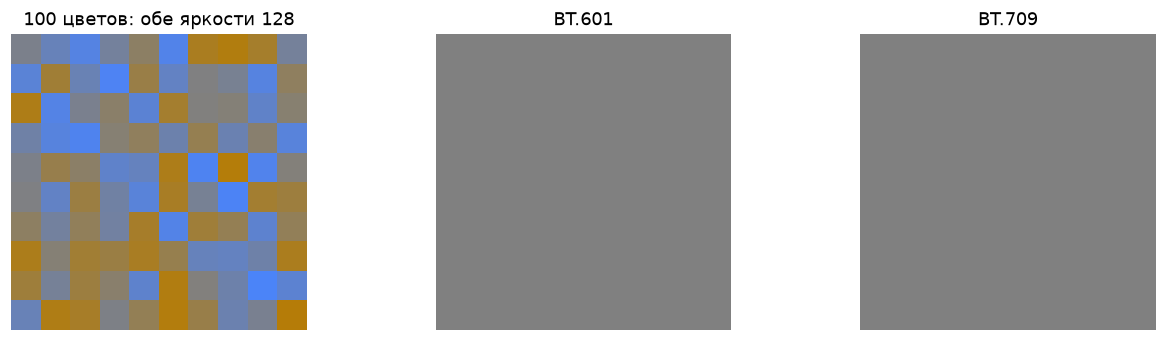

Палитра             диапазон mean    диапазон 601     диапазон 709
BT.601              79.99…176.40  128.00…128.00  102.79…151.80
BT.709              69.66…188.15  108.46…148.69  128.00…128.00
Обе формулы        104.44…151.68  128.00…128.00  128.00…128.00


In [15]:
direction = np.cross(WEIGHTS_601, WEIGHTS_709)
direction /= np.max(np.abs(direction))
t = np.linspace(-120, 120, 100) + rng.uniform(-0.4, 0.4, 100)
rng.shuffle(t)
palette_both = (128 + t[:, None] * direction).reshape(10, 10, 3)


show_images([to_uint8(palette_both), to_uint8(palette_both @ WEIGHTS_601),
             to_uint8(palette_both @ WEIGHTS_709)],
            ['100 цветов: обе яркости 128', 'BT.601', 'BT.709'], cols=3)

print('Палитра             диапазон mean    диапазон 601     диапазон 709')
for name, palette in [('BT.601', palette_601), ('BT.709', palette_709), ('Обе формулы', palette_both)]:
    values = [grayscale_mean(palette), palette @ WEIGHTS_601, palette @ WEIGHTS_709]
    print(f'{name:18s}', '  '.join(f'{v.min():6.2f}…{v.max():6.2f}' for v in values))

## Вывод

Среднее RGB придаёт каждому каналу одинаковый вес. ITU-формулы сильнее учитывают зелёный канал. На цветовых полях визуально предпочтителен BT.709: он передаёт зелёные участки более светлыми, синие — более тёмными. Эта оценка относится к показанной демонстрации и зависит от изображения и экрана.

Равенство яркости проверяется численно. Для исходных `float64`-цветов отклонения находятся на уровне машинного округления. При записи в `uint8` появляется погрешность до 0.5 уровня. Палитра, построенная для одного набора весов, получает разброс яркости при другом наборе. Палитра на пересечении плоскостей сохраняет яркость 128 сразу по двум формулам.

Источники коэффициентов: [ITU-R BT.601](https://www.itu.int/rec/R-REC-BT.601/), [ITU-R BT.709](https://www.itu.int/rec/R-REC-BT.709/). Происхождение изображений приведено в `../data/SOURCES.md`.
